# Quickstart: fitting a sinusoid

This notebook fits a single sinusoid, $s(t) = A \sin(2\pi f t + \phi)$, to
noisy data with `PTSampler`. It covers the whole workflow: writing the
likelihood and prior, running the sampler, reading the chains back, and
checking that the run converged.

Two follow-up notebooks use the same model:

- [Vectorized likelihoods](vectorized_likelihoods.ipynb): batched NumPy,
  JAX and threads.
- [Sampler features](sampler_features.ipynb): tempering on a multimodal
  posterior, periodic parameters, initial covariances, custom proposals
  and checkpoint/resume.

Besides `impulse-mcmc`, this notebook uses `matplotlib` and `corner`.

In [1]:
import corner
import matplotlib.pyplot as plt
import numpy as np

from impulse import PTSampler, autocorr_length_ips_ims, effective_sample_size, grubin

## Simulate the data

1,000 evenly spaced samples over 10 seconds, white Gaussian noise with
$\sigma = 1$, and one sinusoid. The signal-to-noise ratio is about
$A\sqrt{N/2}/\sigma \approx 22$.

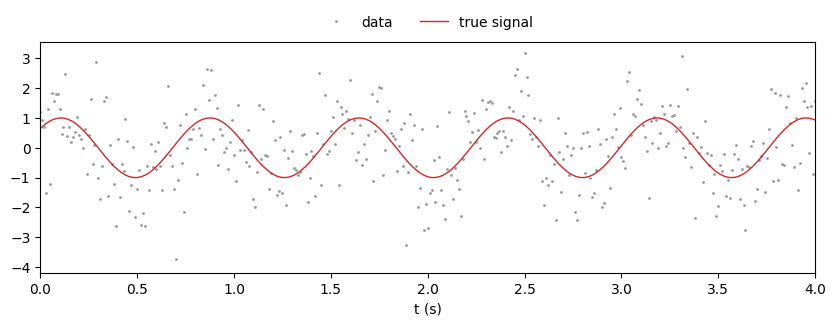

In [2]:
TRUTH = np.array([1.0, 1.3, 0.7])  # amplitude, frequency (Hz), phase (rad)
LABELS = ["A", "f", r"$\phi$"]
SIGMA = 1.0

rng = np.random.default_rng(23)
t = np.linspace(0.0, 10.0, 1000, endpoint=False)
signal = TRUTH[0] * np.sin(2 * np.pi * TRUTH[1] * t + TRUTH[2])
data = signal + SIGMA * rng.standard_normal(t.size)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, data, ".", ms=2, color="0.6", label="data")
ax.plot(t, signal, color="C3", lw=1, label="true signal")
ax.set(xlabel="t (s)", xlim=(0, 4))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, frameon=False);

## Likelihood and prior

Both functions take one parameter vector `x` (shape `(3,)`) and return a
log density. The prior is uniform inside a box and returns `-np.inf`
outside it; the sampler never evaluates the likelihood at a point the
prior rules out. Additive constants don't matter, so both drop them.

In [3]:
LOW = np.array([0.0, 0.05, 0.0])
HIGH = np.array([5.0, 5.0, 2 * np.pi])


def log_likelihood(x):
    a, f, phi = x
    residual = data - a * np.sin(2 * np.pi * f * t + phi)
    return -0.5 * np.dot(residual, residual) / SIGMA**2


def log_prior(x):
    return 0.0 if np.all((x >= LOW) & (x <= HIGH)) else -np.inf

## Run the sampler

`PTSampler` runs `ntemps` chains at different temperatures and swaps
states between them, so hot chains can carry the cold chain between
modes. The cold chain (temperature 1) samples the posterior. Within each
chain, a mixture of adaptive Metropolis (AM), single-component AM (SCAM)
and differential evolution (DE) proposals learns the posterior's shape as
the run goes.

We start from a random point drawn from the prior, so the sampler has to
find the signal on its own. Chains are written to `outdir` as the run
goes, along with a checkpoint every `save_freq` iterations.

In [4]:
sampler = PTSampler(
    ndim=3,
    lnlike=log_likelihood,
    lnprior=log_prior,
    ntemps=8,
    seed=1,
    outdir="chains_quickstart",
    verbose=False,
)
x0 = np.random.default_rng(1).uniform(LOW, HIGH)
print("start:", x0.round(3))
sampler.sample(x0, num_iterations=50_000)

start: [2.559 4.755 0.906]


## Read the chains

`load_chain()` returns arrays with one row per saved iteration for every
temperature: `samples` is `(ntemps, n, ndim)`, and `lnlike`, `lnprob`,
`accepted` and `temperature` are `(ntemps, n)`. Index 0 is the cold chain.

{'samples': (8, 50000, 3), 'lnlike': (8, 50000), 'lnprob': (8, 50000), 'accepted': (8, 50000), 'temperature': (8, 50000)}


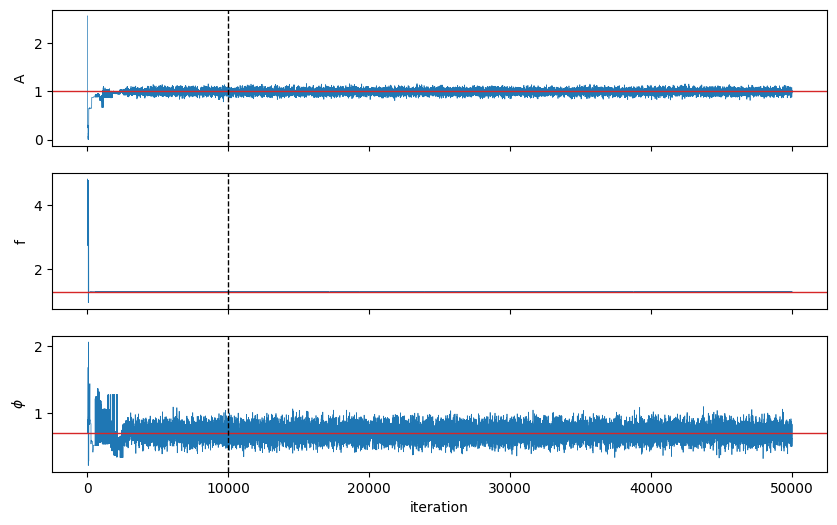

In [5]:
chain = sampler.load_chain()
print({key: value.shape for key, value in chain.items()})

cold = chain["samples"][0]
BURN = 10_000

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(cold[:, i], lw=0.5)
    ax.axhline(TRUTH[i], color="C3", lw=1)
    ax.axvline(BURN, color="k", ls="--", lw=1)
    ax.set_ylabel(LABELS[i])
axes[-1].set_xlabel("iteration");

The chain finds the signal within the first couple of thousand
iterations. We discard the first 10,000 as burn-in, since the proposals
are still adapting then.

   A: 0.9910 +/- 0.0448   (true 1.0)
   f: 1.3008 +/- 0.0025   (true 1.3)
 phi: 0.7095 +/- 0.0952   (true 0.7)


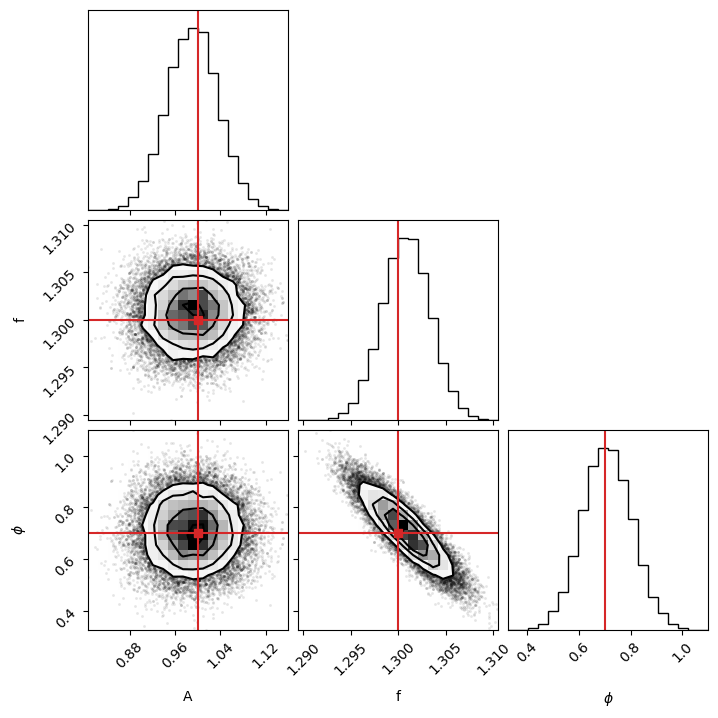

In [6]:
posterior = cold[BURN:]
for label, truth, mean, sd in zip(
    ["A", "f", "phi"], TRUTH, posterior.mean(axis=0), posterior.std(axis=0)
):
    print(f"{label:>4}: {mean:.4f} +/- {sd:.4f}   (true {truth})")

corner.corner(posterior, labels=LABELS, truths=TRUTH, truth_color="C3");

Frequency and phase are strongly correlated: the data constrain the
phase best in the middle of the observation, not at $t = 0$, where
$\phi$ is defined. The adaptive proposals learn this correlation from
the chain history.

## Posterior predictive check

Signals computed from 200 posterior draws, compared with the data.

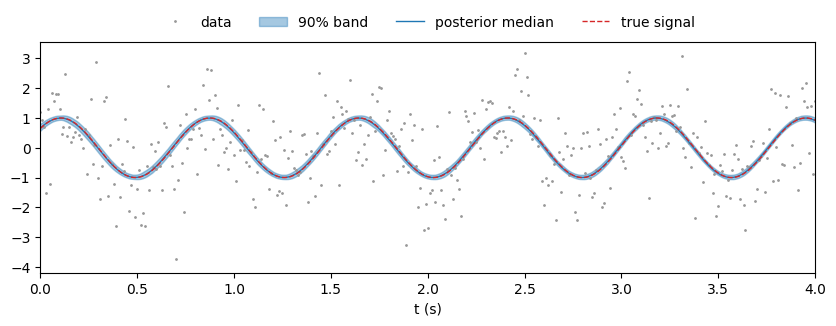

In [7]:
draws = posterior[np.random.default_rng(2).choice(len(posterior), 200)]
models = draws[:, :1] * np.sin(2 * np.pi * draws[:, 1:2] * t + draws[:, 2:3])
lo, mid, hi = np.percentile(models, [5, 50, 95], axis=0)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, data, ".", ms=2, color="0.6", label="data")
ax.fill_between(t, lo, hi, color="C0", alpha=0.4, label="90% band")
ax.plot(t, mid, color="C0", lw=1, label="posterior median")
ax.plot(t, signal, color="C3", lw=1, ls="--", label="true signal")
ax.set(xlabel="t (s)", xlim=(0, 4))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, frameon=False);

## Is the sampler healthy?

Acceptance rates per proposal, summed over all temperatures, and the
swap acceptance between each pair of neighbouring temperatures. The
ladder adapts during the run so that neighbouring chains swap often
enough.

In [8]:
for name, report in sampler.proposal_acceptance_rates().items():
    print(f"{name:>5}: {report['rate']:.2f} of {report['calls']} calls")

rates = sampler.chain_acceptance_rates()
print("temperatures:", np.round(rates["temperatures"], 2))
print("swap rates:  ", np.round(rates["pt_swap"], 2))

   am: 0.08 of 63023 calls
 scam: 0.14 of 126211 calls
   de: 0.40 of 210766 calls
temperatures: [ 1.    1.54  2.39  3.86 18.44 49.13 54.01 65.26]
swap rates:   [0.72 0.72 0.74 0.59 0.32 0.49 0.7 ]


## Has it converged?

- **Autocorrelation length** $\tau$: how many iterations it takes to get
  one roughly independent sample. `autocorr_length_ips_ims` returns two
  estimates (initial positive and initial monotone sequence).
- **Effective sample size**: the number of independent samples the chain
  is worth.
- **$\hat R$** (`grubin`): compares independent runs. Values below about
  1.01 mean the runs agree. We make a second run with a different seed and
  starting point.

In [9]:
tau_ips, tau_ims = autocorr_length_ips_ims(posterior)
print("tau (IPS):", tau_ips.round(1))
print("tau (IMS):", tau_ims.round(1))
print("ESS:      ", effective_sample_size(posterior).round(0))

second = PTSampler(
    ndim=3,
    lnlike=log_likelihood,
    lnprior=log_prior,
    ntemps=8,
    seed=2,
    outdir="chains_quickstart_2",
    verbose=False,
)
second.sample(np.random.default_rng(2).uniform(LOW, HIGH), num_iterations=50_000)
posterior_2 = second.load_chain()["samples"][0][BURN:]

rhat, flagged = grubin([posterior, posterior_2], burn=0)
print("R-hat:    ", np.array2string(rhat, precision=4, floatmode="fixed"))
print("above the 1.01 threshold:", flagged)

tau (IPS): [6.2 5.4 5.7]
tau (IMS): [7.5 7.1 7.6]
ESS:       [6471. 7457. 7053.]


R-hat:     [1.0000 1.0000 1.0000]
above the 1.01 threshold: []


## Where next

- [Vectorized likelihoods](vectorized_likelihoods.ipynb): evaluate all
  temperatures in one call, with NumPy or JAX.
- [Sampler features](sampler_features.ipynb): what tempering buys on a
  multimodal posterior, periodic parameters, initial covariances, custom
  proposals and checkpoint/resume.
- The user guide pages on parallel tempering, checkpointing and custom
  proposals cover each option in more detail.